# Proyecto Final – Modelos – Capital Analyst
## Automatización de algoritmos para el portafolio de Capital Analyst: regresión, datos panel, ARIMA, GARCH y simulación

**Econometría Financiera – FZ4038** · EGADE Business School, Tecnológico de Monterrey  
**Profesor:** Dr. Raymundo Díaz Robles  
**Alumno:** Daniel Mondragón Monroy (A01452205)  
**Fecha:** 9 de noviembre de 2026  
**Repositorio GitHub:** [https://github.com/a01452205/FZ4038-Proyecto-Final](https://github.com/a01452205/FZ4038-Proyecto-Final)

---

<a id="contenido"></a>
**Contenido**

1. [El caso Capital Analyst y objetivo](#sec-1)
2. [Universo de inversión y datos](#sec-2)
    - [2.1 Universo de inversión](#sec-2-1)
    - [2.2 Fuentes y variables](#sec-2-2)
    - [2.3 Calidad de los datos](#sec-2-3)
3. [Métricas de riesgo y rendimiento](#sec-3)
4. [Regresión lineal simple: modelo de mercado](#sec-4)
    - [4.1 Especificación](#sec-4-1)
5. [Regresión lineal múltiple: modelo de factores](#sec-5)
    - [5.1 Selección de variables y signos esperados](#sec-5-1)
    - [5.2 Multicolinealidad de los factores](#sec-5-2)
    - [5.3 Estimación por activo](#sec-5-3)
6. [Datos panel: ¿qué fundamentales explican el rendimiento de las acciones?](#sec-6)
    - [6.1 Planteamiento](#sec-6-1)
    - [6.2 Modelos agrupado, de efectos fijos y de efectos aleatorios](#sec-6-2)
    - [6.3 Elección del modelo: prueba F y prueba de Hausman](#sec-6-3)
    - [6.4 Pruebas de autocorrelación y dependencia transversal](#sec-6-4)
    - [6.5 Modelo final con errores estándar de Driscoll-Kraay](#sec-6-5)
7. [Series de tiempo: ARIMA y pronóstico](#sec-7)
    - [7.1 Ejemplo detallado: Microsoft](#sec-7-1)
    - [7.2 ARIMA para todo el universo](#sec-7-2)
8. [Volatilidad: GARCH (puntos extra)](#sec-8)
9. [Portafolio: covarianza pronosticada, comparación y simulación de escenarios](#sec-9)
    - [9.1 Portafolios comparados](#sec-9-1)
    - [9.2 Simulación de escenarios (Monte Carlo)](#sec-9-2)
10. [Análisis técnico: MACD y RSI](#sec-10)
    - [10.1 Señales al cierre del periodo](#sec-10-1)
    - [10.2 Prueba retrospectiva (backtesting) de la estrategia MACD](#sec-10-2)
11. [Estrategia y propuesta a Capital Analyst](#sec-11)
12. [Evidencias: operaciones en HowTheMarketWorks](#sec-12)
13. [Conclusiones](#sec-13)
14. [Referencias](#sec-14)

<a id="sec-1"></a>
## 1. El caso Capital Analyst y objetivo

<small>[↑ Volver al contenido](#contenido)</small>

**Capital Analyst** es una firma mexicana de asesoría de inversiones que invierte en acciones de México y Estados Unidos y que ha desarrollado algoritmos en R y Python, conectados con plataformas como Interactive Brokers, para apoyar sus decisiones con análisis fundamental, indicadores técnicos y modelos cuantitativos (Díaz Robles, 2023).

En este proyecto se actúa como analista de Capital Analyst. El objetivo es construir, en un solo cuaderno reproducible, el flujo completo que propone el caso:

1. **Datos:** obtener y depurar precios diarios de un universo de 10 acciones estadounidenses y un ETF de petróleo, más los reportes trimestrales de las empresas.
2. **Riesgo y rendimiento:** medir el perfil de cada activo.
3. **Modelos explicativos:** regresión lineal simple y múltiple (qué factores de mercado mueven a cada acción) y datos panel (qué fundamentales de los reportes trimestrales explican el rendimiento de las acciones).
4. **Modelos de pronóstico:** ARIMA para la media y GARCH para la volatilidad, con evaluación fuera de muestra.
5. **Portafolio:** construir portafolios con la covarianza pronosticada, compararlos con el portafolio real y simular escenarios futuros.
6. **Análisis técnico:** señales MACD y RSI y una prueba retrospectiva.
7. **Propuesta a Capital Analyst**, con la estrategia, el horizonte y el nivel de riesgo.

Las relaciones estimadas se interpretan como asociaciones estadísticas útiles para decidir, no como relaciones causales. Ningún resultado es una recomendación de inversión real.

In [1]:
# Paquetes (Colab ya trae numpy, pandas, statsmodels, scipy y matplotlib)
!pip -q install yfinance arch linearmodels

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from arch import arch_model
from linearmodels.panel import PooledOLS, PanelOLS, RandomEffects
from IPython.display import display
warnings.simplefilter("ignore")              # después de importar: statsmodels redefine sus avisos al cargarse

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

def estrellas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

<a id="sec-2"></a>
## 2. Universo de inversión y datos

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-2-1"></a>
### 2.1 Universo de inversión

El universo son las **10 acciones** del portafolio en HowTheMarketWorks y el ETF **USO**, agrupados por sector. Se mantienen las acciones de las actividades de clase (AAPL, MSFT, JPM, GS y XOM, más USO) y se agregan NVDA, GOOGL, BAC, CVX y COP para completar tres sectores comparables, cada uno con al menos tres empresas que reportan estados financieros trimestrales.

| Sector | Activos | Por qué |
|:--|:--|:--|
| Tecnología | AAPL, MSFT, NVDA, GOOGL | Crecimiento y alta capitalización; sensibles al ciclo y a la tasa de descuento |
| Bancos | JPM, GS, BAC | Sensibles a las tasas de interés y al ciclo de crédito |
| Energía | XOM, CVX, COP | Sensibles al precio del petróleo |
| ETF de petróleo | USO | Exposición directa al petróleo (no tiene estados financieros) |

<a id="sec-2-2"></a>
### 2.2 Fuentes y variables

| Variable | Símbolo | Fuente | Uso |
|:--|:--|:--|:--|
| Precio de cierre ajustado diario | $P_{i,t}$ | Yahoo Finance (`yfinance`) | Rendimientos, riesgo, ARIMA, GARCH, portafolio, análisis técnico |
| Rendimiento logarítmico diario (%) | $r_{i,t} = 100\,\Delta\ln P_{i,t}$ | Calculado | Variable dependiente de las regresiones |
| S&P 500 | $r_{m,t}$ | Yahoo Finance (`^GSPC`) | Factor de mercado |
| Tasa del Tesoro a 10 años | $\Delta i_t$ (puntos porcentuales) | Yahoo Finance (`^TNX`) | Factor de tasas |
| Petróleo Brent | $r_{oil,t}$ | Yahoo Finance (`BZ=F`) | Factor petróleo (se usa Brent porque el WTI tuvo un precio negativo en abril de 2020) |
| Índice dólar | $r_{usd,t}$ | Yahoo Finance (`DX-Y.NYB`) | Factor cambiario |
| T-Bill a 3 meses | $r_f$ | Yahoo Finance (`^IRX`) | Tasa libre de riesgo para el índice de Sharpe |
| Reportes trimestrales | Ingresos, utilidad neta, capital común, activo total | LSEG Workspace (2015–2026) | Datos panel |

El periodo es del 2 de enero de 2015 al 6 de noviembre de 2026. La fecha final se fija para que los resultados sean reproducibles.

In [2]:
import yfinance as yf

ACTIVOS = ["AAPL", "MSFT", "NVDA", "GOOGL", "JPM", "GS", "BAC", "XOM", "CVX", "COP", "USO"]
SECTOR = {"AAPL": "Tecnología", "MSFT": "Tecnología", "NVDA": "Tecnología", "GOOGL": "Tecnología",
          "JPM": "Bancos", "GS": "Bancos", "BAC": "Bancos",
          "XOM": "Energía", "CVX": "Energía", "COP": "Energía", "USO": "ETF petróleo"}
FACTORES = {"^GSPC": "mercado", "^TNX": "tasa10", "BZ=F": "brent", "DX-Y.NYB": "dolar", "^IRX": "tbill"}
INICIO, FIN = "2015-01-01", "2026-11-07"           # FIN no se incluye: último dato 6-nov-2026

todo = yf.download(ACTIVOS + list(FACTORES), start=INICIO, end=FIN, auto_adjust=True, progress=False)["Close"]
faltan = [t for t in ACTIVOS + list(FACTORES) if t not in todo.columns or todo[t].dropna().empty]
if faltan:
    raise RuntimeError(f"No se descargaron: {faltan}. Vuelve a correr la celda.")

# Limpieza: los activos y los factores cotizan en calendarios ligeramente distintos (futuros, índices)
precios = todo[ACTIVOS].dropna()
fact_niv = todo[list(FACTORES)].rename(columns=FACTORES).ffill().reindex(precios.index)
if fact_niv["tasa10"].median() > 20:                 # algunas versiones reportan ^TNX multiplicado por 10
    fact_niv["tasa10"] /= 10; fact_niv["tbill"] /= 10

r = 100 * np.log(precios).diff().dropna()            # rendimientos log diarios en %
fact = pd.DataFrame({
    "mercado": 100 * np.log(fact_niv["mercado"]).diff(),
    "tasa10": fact_niv["tasa10"].diff(),              # cambio en puntos porcentuales
    "brent": 100 * np.log(fact_niv["brent"]).diff(),
    "dolar": 100 * np.log(fact_niv["dolar"]).diff(),
}).reindex(r.index)
rf_anual = fact_niv["tbill"].mean()                  # % anual promedio del periodo

print(f"Periodo: {precios.index[0].date()} a {precios.index[-1].date()} | {len(precios):,} días hábiles")
print("Faltantes eliminados en activos:", int(todo[ACTIVOS].isna().any(axis=1).sum()), "días")
print(f"Tasa libre de riesgo promedio (T-Bill 3 meses): {rf_anual:.2f}% anual")
precios.to_csv("precios_diarios_2015_2026.csv")

Periodo: 2015-01-02 a 2026-11-06 | 2,980 días hábiles
Faltantes eliminados en activos: 5 días
Tasa libre de riesgo promedio (T-Bill 3 meses): 2.09% anual


<a id="sec-2-3"></a>
### 2.3 Calidad de los datos

Se verifica que no haya precios no positivos, días faltantes ni rendimientos imposibles, y se revisan los días extremos, que en series financieras suelen ser eventos reales y no errores.

In [3]:
calidad = pd.DataFrame({
    "Observaciones": precios.count(),
    "Precios ≤ 0": (precios <= 0).sum(),
    "Rend. mínimo (%)": r.min().round(2),
    "Fecha mínimo": r.idxmin().dt.date,
    "Rend. máximo (%)": r.max().round(2),
    "Fecha máximo": r.idxmax().dt.date,
})
display(calidad)

,Observaciones,Precios ≤ 0,Rend. mínimo (%),Fecha mínimo,Rend. máximo (%),Fecha máximo
Ticker,,,,,,
AAPL,2980,0,-13.77,2020-03-16,14.26,2025-04-09
MSFT,2980,0,-15.95,2020-03-16,14.42,2026-07-30
NVDA,2980,0,-20.77,2018-11-16,26.09,2016-11-11
GOOGL,2980,0,-13.51,2026-10-29,15.06,2015-07-17
JPM,2980,0,-16.21,2020-03-16,16.56,2020-03-13
GS,2980,0,-13.59,2020-03-16,16.20,2020-03-13
BAC,2980,0,-16.72,2020-03-16,16.38,2020-03-13
XOM,2980,0,-13.04,2020-03-09,11.94,2020-03-24
CVX,2980,0,-25.01,2020-03-18,20.49,2020-03-24


**Interpretación.** Los 11 activos tienen 2,980 observaciones diarias completas y ningún precio no positivo. Los rendimientos extremos son eventos reales, no errores: la mayoría se concentra en **marzo de 2020** (inicio de la pandemia). El peor día de AAPL, MSFT, JPM, GS y BAC fue el 16 de marzo de 2020, y el de XOM, COP y USO, el 9 de marzo de 2020, día del desplome del petróleo. También destaca GOOGL, cuyo peor día es reciente: −13.5% el 29 de octubre de 2026. Como los extremos son reales, no se eliminan; los modelos los tratan con errores estándar robustos y con distribuciones de colas pesadas (sección 8).

<a id="sec-3"></a>
## 3. Métricas de riesgo y rendimiento

<small>[↑ Volver al contenido](#contenido)</small>

Para cada activo se calcula el rendimiento y la volatilidad anualizados (252 días hábiles), el índice de Sharpe con el T-Bill como tasa libre de riesgo, la máxima caída desde un máximo (*maximum drawdown*) y el valor en riesgo (VaR) y el VaR condicional (CVaR) históricos al 95% de un día.

,Sector,Rend. anual (%),Volatilidad anual (%),Sharpe,Máx. caída (%),VaR 95% 1 día (%),CVaR 95% 1 día (%)
AAPL,Tecnología,22.42,28.64,0.71,-38.52,2.74,4.22
MSFT,Tecnología,21.95,27.55,0.72,-37.15,2.69,3.96
NVDA,Tecnología,50.41,47.75,1.01,-66.34,4.51,6.74
GOOGL,Tecnología,20.17,29.22,0.62,-44.32,2.74,4.29
JPM,Bancos,16.81,26.82,0.55,-43.63,2.54,3.93
GS,Bancos,14.60,29.41,0.43,-48.75,2.67,4.30
BAC,Bancos,10.68,30.26,0.28,-48.95,2.85,4.44
XOM,Energía,9.07,27.51,0.25,-61.34,2.63,4.06
CVX,Energía,9.61,29.08,0.26,-55.77,2.64,4.19
COP,Energía,8.96,37.72,0.18,-70.66,3.49,5.45


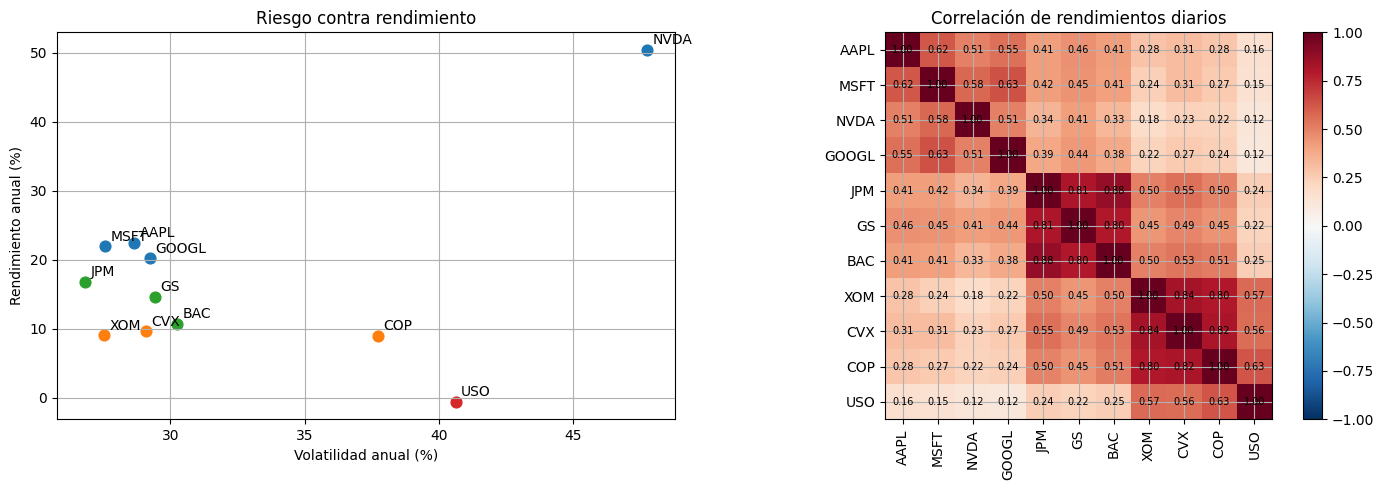

In [4]:
def max_caida(serie_precio):
    return (serie_precio / serie_precio.cummax() - 1).min() * 100

riesgo = pd.DataFrame({
    "Sector": pd.Series(SECTOR),
    "Rend. anual (%)": r.mean() * 252,
    "Volatilidad anual (%)": r.std() * np.sqrt(252),
    "Sharpe": (r.mean() * 252 - rf_anual) / (r.std() * np.sqrt(252)),
    "Máx. caída (%)": precios.apply(max_caida),
    "VaR 95% 1 día (%)": -r.quantile(0.05),
    "CVaR 95% 1 día (%)": -r[r <= r.quantile(0.05)].mean(),
}).loc[ACTIVOS]
display(riesgo.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
colores = {"Tecnología": "tab:blue", "Bancos": "tab:green", "Energía": "tab:orange", "ETF petróleo": "tab:red"}
for k in ACTIVOS:
    ax[0].scatter(riesgo.loc[k, "Volatilidad anual (%)"], riesgo.loc[k, "Rend. anual (%)"], s=60, color=colores[SECTOR[k]])
    ax[0].annotate(k, (riesgo.loc[k, "Volatilidad anual (%)"], riesgo.loc[k, "Rend. anual (%)"]), xytext=(4, 4), textcoords="offset points")
ax[0].set_xlabel("Volatilidad anual (%)"); ax[0].set_ylabel("Rendimiento anual (%)"); ax[0].set_title("Riesgo contra rendimiento")
corr = r.corr()
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(ACTIVOS))); ax[1].set_xticklabels(ACTIVOS, rotation=90)
ax[1].set_yticks(range(len(ACTIVOS))); ax[1].set_yticklabels(ACTIVOS)
for i in range(len(ACTIVOS)):
    for j in range(len(ACTIVOS)):
        ax[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax[1].set_title("Correlación de rendimientos diarios"); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

**Interpretación.**
- **Tecnología** domina en rendimiento ajustado por riesgo. **NVDA** es el caso extremo: 50.4% de rendimiento anual con 47.8% de volatilidad, el mejor Sharpe (1.01), pero también una caída máxima de −66%. AAPL y MSFT tienen Sharpe cercano a 0.7 con volatilidades menores (27–29%).
- **Bancos** ocupan una posición intermedia: JPM es el mejor del grupo (Sharpe 0.55) y BAC el más débil (0.28).
- **Energía** tiene volatilidad similar a la de tecnología pero rendimientos de solo 9–10% anual, con Sharpe de 0.18 a 0.26 y caídas máximas de −56% a −71%.
- **USO** es el peor activo: rendimiento negativo (−0.6% anual), Sharpe negativo y una caída máxima de **−90%**, por el costo de renovar sus contratos de futuros y el desplome de 2020.
- **Correlaciones:** los activos del mismo sector están mucho más correlacionados entre sí que con los de otros sectores. Combinar sectores reduce el riesgo del portafolio (sección 9).

<a id="sec-4"></a>
## 4. Regresión lineal simple: modelo de mercado

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-4-1"></a>
### 4.1 Especificación

¿Qué parte del movimiento de cada acción se explica por el mercado? Se estima el **modelo de mercado** (la versión empírica del CAPM) para cada activo $i$:

$$r_{i,t} = \alpha_i + \beta_i\, r_{m,t} + u_{i,t}$$

- **Variable dependiente:** rendimiento diario de la acción $r_{i,t}$ (%), una variable continua.
- **Variable independiente:** rendimiento diario del S&P 500 $r_{m,t}$ (%). Se elige porque, según el CAPM, el riesgo sistemático es el único que el mercado remunera, y el S&P 500 es el índice de referencia de las acciones estadounidenses.
- **$\beta_i$** mide la sensibilidad al mercado: $\beta > 1$ es una acción **agresiva**, $\beta < 1$ es **defensiva**.
- **$\alpha_i$** es el rendimiento diario no explicado por el mercado.
- **$R^2$** separa el riesgo total en **sistemático** (proporción $R^2$) e **idiosincrático** ($1 - R^2$), que se puede diversificar.

Como en la Tarea Clase 6 – 2.1 se encontraron efectos ARCH en todos los activos, los errores estándar se calculan con el método de **Newey-West (HAC)**, robusto a heteroscedasticidad y autocorrelación.

In [5]:
def pruebas(modelo, X):
    resid = modelo.resid
    return {"BP (p)": het_breuschpagan(resid, X)[1],
            "BG 5 rez. (p)": acorr_breusch_godfrey(modelo, nlags=5)[1],
            "JB (p)": jarque_bera(resid)[1],
            "DW": durbin_watson(resid)}

filas, mod_simple = [], {}
for k in ACTIVOS:
    datos = pd.concat([r[k], fact["mercado"]], axis=1).dropna()
    X = sm.add_constant(datos["mercado"])
    ols = sm.OLS(datos[k], X).fit()
    hac = sm.OLS(datos[k], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    mod_simple[k] = hac
    filas.append({"Activo": k, "Sector": SECTOR[k],
                  "α diario (%)": hac.params["const"], "p α": hac.pvalues["const"],
                  "β": hac.params["mercado"], "t β (HAC)": hac.tvalues["mercado"], "p β": hac.pvalues["mercado"],
                  "R²": ols.rsquared, "Riesgo sistemático (%)": 100 * ols.rsquared, **pruebas(ols, X)})
simple = pd.DataFrame(filas).set_index("Activo")
display(simple.round(4))

,Sector,α diario (%),p α,β,t β (HAC),p β,R²,Riesgo sistemático (%),BP (p),BG 5 rez. (p),JB (p),DW
Activo,,,,,,,,,,,,
AAPL,Tecnología,0.0387,0.1035,1.1743,37.5198,0.0,0.5260,52.6036,0.1186,0.0054,0.0,1.8625
MSFT,Tecnología,0.0366,0.0763,1.1783,44.9789,0.0,0.5726,57.2562,0.4697,0.3160,0.0,1.9928
NVDA,Tecnología,0.1245,0.0022,1.7627,26.7341,0.0,0.4266,42.6566,0.6329,0.3515,0.0,2.0749
GOOGL,Tecnología,0.0310,0.2038,1.1441,29.6383,0.0,0.4798,47.9821,0.8105,0.1243,0.0,1.9391
JPM,Bancos,0.0204,0.3332,1.0813,27.7645,0.0,0.5089,50.8888,0.3494,0.3862,0.0,2.0315
GS,Bancos,0.0055,0.8040,1.2235,42.9331,0.0,0.5418,54.1834,0.6581,0.4287,0.0,2.0328
BAC,Bancos,-0.0086,0.7389,1.1911,29.3047,0.0,0.4849,48.4911,0.4849,0.0992,0.0,1.8969
XOM,Energía,0.0034,0.9037,0.7609,16.2178,0.0,0.2394,23.9432,0.7014,0.0002,0.0,1.9515
CVX,Energía,-0.0004,0.9900,0.8978,12.3290,0.0,0.2984,29.8397,0.0002,0.3272,0.0,1.9859


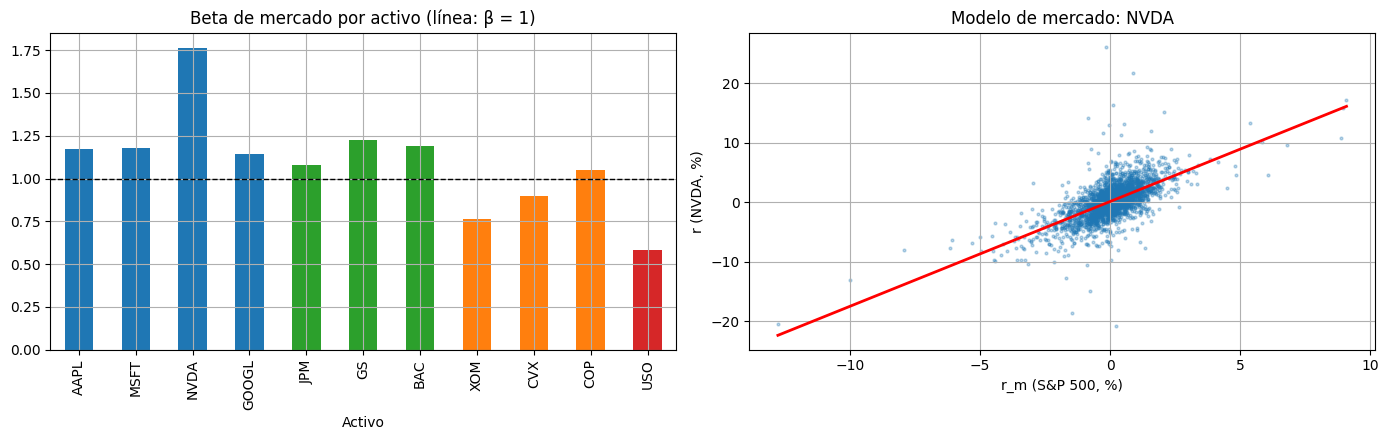

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
simple["β"].plot.bar(ax=ax[0], color=[colores[SECTOR[k]] for k in simple.index])
ax[0].axhline(1, color="k", ls="--", lw=1); ax[0].set_title("Beta de mercado por activo (línea: β = 1)")
k = "NVDA"
datos = pd.concat([r[k], fact["mercado"]], axis=1).dropna()
ax[1].scatter(datos["mercado"], datos[k], s=4, alpha=0.3)
xs = np.linspace(datos["mercado"].min(), datos["mercado"].max(), 50)
ax[1].plot(xs, mod_simple[k].params["const"] + mod_simple[k].params["mercado"] * xs, "r", lw=2)
ax[1].set_xlabel("r_m (S&P 500, %)"); ax[1].set_ylabel(f"r ({k}, %)"); ax[1].set_title(f"Modelo de mercado: {k}")
plt.tight_layout(); plt.show()

**Lectura de las pruebas.** BP = Breusch-Pagan ($H_0$: varianza constante); BG = Breusch-Godfrey con 5 rezagos ($H_0$: sin autocorrelación); JB = Jarque-Bera ($H_0$: residuos normales); DW = Durbin-Watson (cercano a 2: sin autocorrelación de primer orden).



**Interpretación.**
- **β de mercado.** Las 10 acciones tienen un β significativo y positivo. Tecnología y bancos son **agresivos** ($\beta > 1$): NVDA tiene el β más alto (1.76), seguido de GS (1.22), BAC (1.19), MSFT (1.18) y AAPL (1.17). Energía es **defensiva** ($\beta$ de 0.76 en XOM a 1.05 en COP) y USO tiene el β más bajo (0.58).
- **Riesgo sistemático.** El mercado explica entre 43% y 57% de la variación diaria en tecnología y bancos, pero solo 24–30% en energía y **6%** en USO. En energía la mayor parte del riesgo es propio del sector, lo que motiva el modelo de factores de la sección 5.
- **α.** Solo **NVDA** tiene un α significativo (0.125% diario, p = 0.002): un rendimiento extraordinario de alrededor de 30% anual que el mercado no explica, asociado al auge de la inteligencia artificial. En las demás acciones α no es distinto de cero, como predice el CAPM.
- **Pruebas.** Jarque-Bera rechaza la normalidad en todos los casos (colas pesadas); Breusch-Pagan y Breusch-Godfrey rechazan en algunos activos (CVX, COP, USO, AAPL, XOM). Por eso las conclusiones se basan en los errores robustos de Newey-West; con casi 3,000 observaciones, la falta de normalidad no invalida la inferencia.

<a id="sec-5"></a>
## 5. Regresión lineal múltiple: modelo de factores

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-5-1"></a>
### 5.1 Selección de variables y signos esperados

El mercado no explica todo. Se agregan **tres factores macro-financieros** que la teoría y la composición sectorial del universo hacen relevantes:

$$r_{i,t} = \alpha_i + \beta_{1i}\, r_{m,t} + \beta_{2i}\, \Delta i_t + \beta_{3i}\, r_{oil,t} + \beta_{4i}\, r_{usd,t} + u_{i,t}$$

| Factor | Por qué se incluye | Signo esperado |
|:--|:--|:--|
| Mercado $r_{m,t}$ | Riesgo sistemático (CAPM) | + en todos |
| Cambio en la tasa a 10 años $\Delta i_t$ | Las tasas más altas elevan el margen de interés de los **bancos** y reducen el valor presente de los flujos lejanos de las empresas de **tecnología** (acciones de "larga duración") | + bancos, − tecnología |
| Petróleo Brent $r_{oil,t}$ | Determina los ingresos de las petroleras y de USO | + energía y USO; ≈ 0 en los demás |
| Índice dólar $r_{usd,t}$ | Un dólar fuerte reduce el valor en dólares de las ventas en el extranjero (tecnología) y abarata las materias primas | − tecnología y energía |

**Variable descartada a priori:** el índice de volatilidad VIX. Su correlación con el rendimiento del mercado suele ser cercana a −0.7, por lo que agregaría multicolinealidad sin aportar información distinta del factor de mercado.

<a id="sec-5-2"></a>
### 5.2 Multicolinealidad de los factores

In [7]:
F = fact[["mercado", "tasa10", "brent", "dolar"]].dropna()
Xf = sm.add_constant(F)
vif = pd.DataFrame({"VIF": [variance_inflation_factor(Xf.values, i) for i in range(1, Xf.shape[1])]}, index=F.columns)
display(F.corr().round(2)); display(vif.round(2))

,mercado,tasa10,brent,dolar
mercado,1.00,0.14,0.21,-0.10
tasa10,0.14,1.00,0.21,0.29
brent,0.21,0.21,1.00,-0.03
dolar,-0.10,0.29,-0.03,1.00


,VIF
mercado,1.08
tasa10,1.17
brent,1.09
dolar,1.12


**Interpretación.** Las correlaciones entre factores son bajas (máximo 0.29, entre tasa y dólar) y todos los VIF están entre 1.08 y 1.17, muy por debajo de los umbrales habituales de 5 o 10: **no hay multicolinealidad**, y cada coeficiente mide un efecto distinguible.

<a id="sec-5-3"></a>
### 5.3 Estimación por activo

In [8]:
filas, mod_mult = [], {}
for k in ACTIVOS:
    datos = pd.concat([r[k], F], axis=1).dropna()
    X = sm.add_constant(datos[F.columns])
    ols = sm.OLS(datos[k], X).fit()
    hac = sm.OLS(datos[k], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    mod_mult[k] = hac
    wald = hac.wald_test("tasa10 = 0, brent = 0, dolar = 0", scalar=True)
    fila = {"Activo": k, "Sector": SECTOR[k]}
    for v in F.columns:
        fila[v] = f"{hac.params[v]:.3f}{estrellas(hac.pvalues[v])}"
    fila.update({"R² simple": simple.loc[k, "R²"], "R² múltiple": ols.rsquared, "R² aj. múltiple": ols.rsquared_adj,
                 "p factores adicionales (Wald HAC)": float(wald.pvalue), **pruebas(ols, X)})
    filas.append(fila)
mult = pd.DataFrame(filas).set_index("Activo")
display(mult.round(4))
print("Significancia con errores HAC: *** 1%, ** 5%, * 10%. Coeficientes: tasa10 en % por punto porcentual; los demás son elasticidades diarias.")

,Sector,mercado,tasa10,brent,dolar,R² simple,R² múltiple,R² aj. múltiple,p factores adicionales (Wald HAC),BP (p),BG 5 rez. (p),JB (p),DW
Activo,,,,,,,,,,,,,
AAPL,Tecnología,1.192***,-0.881,-0.014,0.135**,0.5260,0.5278,0.5272,0.0180,0.4654,0.0096,0.0,1.8693
MSFT,Tecnología,1.202***,-0.896*,-0.022**,0.175***,0.5726,0.5759,0.5753,0.0007,0.2688,0.2037,0.0,1.9882
NVDA,Tecnología,1.798***,-1.432,-0.036**,0.219**,0.4266,0.4289,0.4281,0.0052,0.6701,0.3795,0.0,2.0741
GOOGL,Tecnología,1.171***,-0.978*,-0.037***,0.044,0.4798,0.4838,0.4831,0.0003,0.6642,0.0825,0.0,1.9352
JPM,Bancos,1.029***,6.193***,0.018,-0.039,0.5089,0.5478,0.5472,0.0000,0.0009,0.0985,0.0,2.0532
GS,Bancos,1.195***,3.464***,0.007,-0.055,0.5418,0.5514,0.5508,0.0000,0.0230,0.2000,0.0,2.0388
BAC,Bancos,1.128***,7.497***,0.023*,-0.015,0.4849,0.5308,0.5301,0.0000,0.1053,0.1779,0.0,1.9293
XOM,Energía,0.595***,2.914***,0.286***,-0.085,0.2394,0.4391,0.4383,0.0000,0.1814,0.0118,0.0,2.0256
CVX,Energía,0.738***,1.815*,0.287***,-0.107*,0.2984,0.4696,0.4689,0.0000,0.0000,0.0415,0.0,2.0790


Significancia con errores HAC: *** 1%, ** 5%, * 10%. Coeficientes: tasa10 en % por punto porcentual; los demás son elasticidades diarias.


**Interpretación.**
- **Tasas de interés: separan a bancos y tecnología, como se esperaba.** En los tres bancos el coeficiente es **positivo y significativo al 1%** (JPM 6.19, BAC 7.50, GS 3.46): un alza de 10 puntos base en la tasa a 10 años se asocia con un rendimiento adicional de 0.35% a 0.75% ese día. En tecnología el signo es **negativo**, como acciones de "larga duración", aunque solo es significativo al 10% en MSFT y GOOGL. Energía también responde positivamente a las tasas, probablemente porque las tasas suben en etapas de crecimiento e inflación, que favorecen al petróleo.
- **Petróleo: domina en energía.** El Brent es muy significativo en XOM (0.29), CVX (0.29), COP (0.45) y USO (**0.86**). En tecnología el efecto es pequeño y negativo (el petróleo caro es un costo para la economía).
- **Dólar: resultado contrario a lo esperado.** En tecnología el coeficiente es **positivo** y significativo (AAPL 0.14, MSFT 0.18, NVDA 0.22), cuando se esperaba negativo por las ventas en el extranjero. Una explicación posible, no verificada, es que en el periodo el dólar se fortaleció en momentos de entrada de capital hacia activos estadounidenses, incluidas las grandes tecnológicas. Es un hallazgo que conviene reportar como tal.
- **Ganancia de ajuste.** Los tres factores adicionales son conjuntamente significativos en los 11 activos (Wald robusto, p < 0.05). La ganancia es enorme en energía (el R² de XOM pasa de 0.24 a 0.44 y el de COP de 0.24 a 0.50) y sobre todo en **USO, de 0.06 a 0.81**; moderada en bancos (unos 4 a 5 puntos); y mínima en tecnología (menos de 1 punto), cuyo riesgo es casi todo de mercado.
- **Implicación para Capital Analyst:** el riesgo de cada sector tiene un motor distinto (mercado en tecnología, tasas en bancos, petróleo en energía). Un portafolio que combina los tres sectores diversifica esos motores.

<a id="sec-6"></a>
## 6. Datos panel: ¿qué fundamentales explican el rendimiento de las acciones?

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-6-1"></a>
### 6.1 Planteamiento

Capital Analyst usa los reportes trimestrales para decidir. La pregunta es: **¿los fundamentales que reporta cada empresa se asocian con el rendimiento de su acción en el trimestre siguiente**, que es cuando el mercado conoce el reporte?

Se usa un panel de **10 empresas** (USO no tiene estados financieros) con datos trimestrales de LSEG. La variable dependiente y las explicativas son:

| Variable | Definición | Signo esperado |
|:--|:--|:--|
| $ret_{i,t+1}$ | Rendimiento logarítmico (%) de la acción en el trimestre $t+1$ | (dependiente) |
| $crec_{i,t}$ | Crecimiento interanual de los ingresos: $100\,\ln(Ing_{i,t}/Ing_{i,t-4})$. Interanual para eliminar la estacionalidad | + |
| $roe_{i,t}$ | ROE trimestral anualizado: $400 \times$ utilidad neta de la controladora ÷ capital común | + |
| $apal_{i,t}$ | Apalancamiento: activo total ÷ capital común. Funciona igual para bancos y no bancos, a diferencia de la deuda total (en los bancos la mayor parte del pasivo son depósitos) | ambiguo (más rentabilidad y más riesgo) |
| $r_{m,t+1}$ | Rendimiento del S&P 500 en $t+1$ (control de mercado) | + |

Los trimestres fiscales de AAPL y NVDA se alinean con el trimestre calendario que contiene la mitad del periodo. Se sigue la metodología de la Tarea 6: modelo agrupado, efectos fijos y efectos aleatorios; prueba F y de Hausman; pruebas de Wooldridge y de Pesaran; y errores estándar de Driscoll-Kraay.

In [9]:
# Datos trimestrales de LSEG (archivo del repositorio; si existe una copia local en Colab, se usa esa)
URL = "https://raw.githubusercontent.com/a01452205/FZ4038-Proyecto-Final/main/panel_trimestral_LSEG.csv"
import os
fuente = "panel_trimestral_LSEG.csv" if os.path.exists("panel_trimestral_LSEG.csv") else URL
lseg = pd.read_csv(fuente, parse_dates=["fecha_cierre"])
print("Fuente:", fuente, "|", lseg.shape)

lseg = lseg.sort_values(["ticker", "trimestre"])
lseg["crec"] = 100 * np.log(lseg["ingresos"] / lseg.groupby("ticker")["ingresos"].shift(4))
lseg["roe"] = 400 * lseg["utilidad_neta"] / lseg["capital_comun"]
lseg["apal"] = lseg["activo_total"] / lseg["capital_comun"]

# Rendimiento trimestral de la acción y del mercado en el trimestre siguiente
pq = np.log(pd.concat([precios, fact_niv["mercado"]], axis=1)).groupby(precios.index.to_period("Q")).last()
rq = 100 * pq.diff()
rq.index = rq.index.astype(str)
sig = rq.shift(-1)                                    # rendimiento del trimestre t+1
lseg["ret_sig"] = [sig.loc[q, t] if q in sig.index else np.nan for t, q in zip(lseg["ticker"], lseg["trimestre"])]
lseg["mkt_sig"] = [sig.loc[q, "mercado"] if q in sig.index else np.nan for q in lseg["trimestre"]]

panel = lseg.dropna(subset=["crec", "roe", "apal", "ret_sig", "mkt_sig"]).copy()
panel["periodo"] = pd.PeriodIndex(panel["trimestre"], freq="Q").to_timestamp()
panel = panel.set_index(["ticker", "periodo"])
print(f"Panel: {panel.index.get_level_values(0).nunique()} empresas, "
      f"{panel.index.get_level_values(1).nunique()} trimestres, {len(panel)} observaciones")
display(panel[["ret_sig", "crec", "roe", "apal", "mkt_sig"]].describe().T.round(2))

Fuente: https://raw.githubusercontent.com/a01452205/FZ4038-Proyecto-Final/main/panel_trimestral_LSEG.csv | (479, 8)
Panel: 10 empresas, 45 trimestres, 439 observaciones


,count,mean,std,min,25%,50%,75%,max
ret_sig,439.0,5.01,16.48,-74.33,-3.67,5.55,14.32,64.24
crec,439.0,10.83,26.02,-105.66,-0.75,9.55,18.93,129.55
roe,439.0,28.98,37.12,-51.08,10.75,16.82,32.87,217.68
apal,439.0,5.31,5.01,1.19,1.72,2.12,10.91,19.39
mkt_sig,439.0,2.95,7.82,-22.32,0.77,3.85,7.91,18.19


<a id="sec-6-2"></a>
### 6.2 Modelos agrupado, de efectos fijos y de efectos aleatorios

In [10]:
y = panel["ret_sig"]
X = sm.add_constant(panel[["crec", "roe", "apal", "mkt_sig"]])
pooled = PooledOLS(y, X).fit()
fe = PanelOLS(y, X, entity_effects=True).fit()
re = RandomEffects(y, X).fit()

def tabla_panel(res, nombre):
    return pd.DataFrame({f"{nombre}: coef.": res.params, f"{nombre}: p": res.pvalues})
comp = pd.concat([tabla_panel(pooled, "Agrupado"), tabla_panel(fe, "Efectos fijos"), tabla_panel(re, "Efectos aleatorios")], axis=1)
display(comp.round(4))
print(f"R² (within) efectos fijos: {fe.rsquared_within:.3f} | R² agrupado: {pooled.rsquared:.3f}")

,Agrupado: coef.,Agrupado: p,Efectos fijos: coef.,Efectos fijos: p,Efectos aleatorios: coef.,Efectos aleatorios: p
const,0.7446,0.5243,0.8675,0.8051,0.7446,0.5243
crec,0.1100,0.0000,0.1052,0.0003,0.1100,0.0000
roe,0.0010,0.9564,-0.0636,0.0368,0.0010,0.9564
apal,-0.0875,0.5039,0.2578,0.7018,-0.0875,0.5039
mkt_sig,1.1877,0.0000,1.1772,0.0000,1.1877,0.0000


R² (within) efectos fijos: 0.333 | R² agrupado: 0.333


<a id="sec-6-3"></a>
### 6.3 Elección del modelo: prueba F y prueba de Hausman

- **Prueba F (efectos fijos contra agrupado):** $H_0$ = los efectos individuales de las empresas son todos iguales (el modelo agrupado es adecuado).
- **Prueba de Hausman (efectos fijos contra aleatorios):** $H_0$ = los efectos individuales no están correlacionados con las variables explicativas (efectos aleatorios es consistente y eficiente).

In [11]:
fp = fe.f_pooled
print(f"Prueba F de efectos individuales: F = {fp.stat:.3f}, p = {fp.pval:.4f}")

comunes = ["crec", "roe", "apal", "mkt_sig"]
b = fe.params[comunes] - re.params[comunes]
V = fe.cov.loc[comunes, comunes] - re.cov.loc[comunes, comunes]
h = float(b.T @ np.linalg.pinv(V) @ b)
p_h = 1 - stats.chi2.cdf(h, len(comunes))
print(f"Prueba de Hausman: χ² = {h:.3f}, gl = {len(comunes)}, p = {p_h:.4f}")

Prueba F de efectos individuales: F = 1.617, p = 0.1079
Prueba de Hausman: χ² = 13.862, gl = 4, p = 0.0077


**Interpretación.**
- **Prueba F:** no rechaza al 5% (p = 0.108), aunque sí al 11%. Por sí sola sugeriría que el modelo agrupado es suficiente.
- **Prueba de Hausman:** **rechaza** (p = 0.008). Los efectos individuales de las empresas sí están correlacionados con las variables explicativas: por ejemplo, los bancos tienen apalancamientos estructuralmente más altos y las tecnológicas ROE más altos. Con esa correlación, efectos aleatorios es inconsistente, y también lo sería el modelo agrupado si los efectos existen.
- **Decisión:** se elige **efectos fijos**. Es consistente tanto si los efectos individuales existen como si no; con 45 trimestres por empresa, el costo en eficiencia es pequeño; y la prueba F está cerca del umbral, con poca potencia por tener solo 10 empresas. La diferencia importa: el coeficiente del ROE cambia de signo y de significancia entre el modelo agrupado y el de efectos fijos.

<a id="sec-6-4"></a>
### 6.4 Pruebas de autocorrelación y dependencia transversal

- **Wooldridge (autocorrelación en panel):** en primeras diferencias, si los errores no están autocorrelacionados, la correlación entre residuos consecutivos es −0.5. $H_0$: no hay autocorrelación serial.
- **Pesaran CD (dependencia transversal):** $H_0$: los residuos de las distintas empresas no están correlacionados en el mismo trimestre. Con empresas que comparten choques de mercado se espera rechazarla.

In [12]:
# Wooldridge: regresión en primeras diferencias y prueba de que la autocorrelación de sus residuos es -0.5
dpanel = panel[["ret_sig", "crec", "roe", "apal", "mkt_sig"]].groupby(level=0).diff().dropna()
m_d = sm.OLS(dpanel["ret_sig"], dpanel[["crec", "roe", "apal", "mkt_sig"]]).fit()
e = m_d.resid
e_lag = e.groupby(level=0).shift(1)
dd = pd.concat([e.rename("e"), e_lag.rename("e1")], axis=1).dropna()
m_w = sm.OLS(dd["e"], dd["e1"]).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(dd.index.get_level_values(0))[0]})
w_stat = ((m_w.params["e1"] + 0.5) / m_w.bse["e1"]) ** 2
print(f"Wooldridge: coef. = {m_w.params['e1']:.3f} (bajo H0: -0.5), F = {w_stat:.3f}, p = {1 - stats.chi2.cdf(w_stat, 1):.4f}")

# Pesaran CD sobre los residuos de efectos fijos
res_fe = fe.resids.unstack(level=0)
N, T = res_fe.shape[1], res_fe.shape[0]
rho = res_fe.corr(min_periods=8).values
suma = np.nansum(np.triu(rho, 1))
cd = np.sqrt(2 * T / (N * (N - 1))) * suma
print(f"Pesaran CD = {cd:.3f}, p = {2 * (1 - stats.norm.cdf(abs(cd))):.4f} | correlación promedio entre empresas = {np.nanmean(rho[np.triu_indices(N, 1)]):.3f}")

Wooldridge: coef. = -0.539 (bajo H0: -0.5), F = 0.813, p = 0.3673
Pesaran CD = 2.899, p = 0.0037 | correlación promedio entre empresas = 0.064


**Interpretación.**
- **Wooldridge:** no rechaza (p = 0.37); el coeficiente estimado (−0.54) es cercano al −0.5 que implica la ausencia de autocorrelación. Es lógico: la variable dependiente es un rendimiento trimestral, casi impredecible a partir del trimestre anterior.
- **Pesaran CD:** **rechaza** (p = 0.004). Aun controlando por el rendimiento del mercado, los residuos de las empresas están correlacionados en el mismo trimestre (correlación promedio de 0.06), por choques comunes que no capta el S&P 500 (por ejemplo, choques sectoriales).
- Por la dependencia transversal, los errores estándar convencionales no son confiables, y se usan los de **Driscoll-Kraay**.

<a id="sec-6-5"></a>
### 6.5 Modelo final con errores estándar de Driscoll-Kraay

Los errores de Driscoll-Kraay son robustos a heteroscedasticidad, autocorrelación y dependencia transversal, por lo que son los adecuados cuando las pruebas anteriores detectan problemas (Hoechle, 2007).

In [13]:
# Regla de decisión: efectos fijos si la prueba F o la de Hausman rechazan (p < 0.05); si no, el modelo agrupado.
# (Efectos fijos es consistente haya o no efectos individuales; con más de 40 trimestres por empresa su costo en eficiencia es pequeño.)
usar_fe = (fp.pval < 0.05) or (p_h < 0.05)
print("Modelo final:", "efectos fijos" if usar_fe else "agrupado", "con errores de Driscoll-Kraay")
dk = PanelOLS(y, X, entity_effects=usar_fe).fit(cov_type="kernel")
tabla_dk = pd.DataFrame({"Coeficiente": dk.params, "Error est. (DK)": dk.std_errors, "t": dk.tstats, "p": dk.pvalues})
tabla_dk["Sig."] = tabla_dk["p"].apply(estrellas)
display(tabla_dk.round(4))
print(f"R² = {dk.rsquared:.3f} | R² within = {dk.rsquared_within:.3f} | N = {dk.nobs}")

Modelo final: efectos fijos con errores de Driscoll-Kraay


,Coeficiente,Error est. (DK),t,p,Sig.
const,0.8675,3.7897,0.2289,0.8191,
crec,0.1052,0.0555,1.8950,0.0588,*
roe,-0.0636,0.0271,-2.3512,0.0192,**
apal,0.2578,0.6526,0.3951,0.6930,
mkt_sig,1.1772,0.1410,8.3462,0.0000,***


R² = 0.333 | R² within = 0.333 | N = 439


**Interpretación del modelo final (efectos fijos con errores de Driscoll-Kraay).**

- **Mercado ($r_{m,t+1}$):** coeficiente de 1.18, muy significativo. El factor que más explica el rendimiento trimestral de una acción es el del mercado en ese mismo trimestre, lo que confirma los resultados de las secciones 4 y 5.
- **Crecimiento de ingresos ($crec$):** positivo (0.105) y significativo al 10% (p = 0.059). Un punto porcentual más de crecimiento interanual de los ingresos se asocia con 0.11 puntos más de rendimiento en el trimestre en que se publica el reporte: **el mercado premia el crecimiento.**
- **ROE ($roe$):** negativo (−0.064) y significativo al 5% (p = 0.019). Dentro de cada empresa, los trimestres con un ROE más alto que su promedio van seguidos de rendimientos menores. Una lectura consistente con la teoría es la **reversión a la media**: el mercado ya descontó la rentabilidad alta en el precio, y un ROE excepcional tiende a normalizarse. No implica que las empresas rentables sean malas inversiones; habla de las variaciones respecto de su propio promedio.
- **Apalancamiento ($apal$):** no significativo. El nivel de apalancamiento no explica el rendimiento una vez que se controla por la empresa y el mercado.
- **Ajuste:** el modelo explica alrededor de un tercio de la variación de los rendimientos trimestrales dentro de cada empresa (R² *within* = 0.33), la mayor parte por el mercado.
- **Con errores de Driscoll-Kraay los errores estándar crecen** (por ejemplo, el del crecimiento pasa de 0.03 a 0.06), lo que muestra la importancia de corregir la dependencia transversal: con errores convencionales se habría sobrestimado la significancia.

**Implicación para Capital Analyst:** los reportes trimestrales sí contienen información, sobre todo el **crecimiento de ingresos**, pero su poder explicativo es pequeño frente al del mercado. Conviene usarlos para seleccionar acciones con crecimiento, no para anticipar el rendimiento de un trimestre.

<a id="sec-7"></a>
## 7. Series de tiempo: ARIMA y pronóstico

<small>[↑ Volver al contenido](#contenido)</small>

Se sigue la metodología Box-Jenkins del capítulo 22 de Gujarati y Porter (2009) y el cuaderno guía del curso: **identificación** (estacionariedad, ACF y PACF), **estimación**, **verificación diagnóstica** (residuos ruido blanco) y **pronóstico**. La Tarea Clase 6 – 2.1 mostró que los log-precios son $I(1)$ y los rendimientos $I(0)$, por lo que se usa $d = 1$ sobre el log-precio.

<a id="sec-7-1"></a>
### 7.1 Ejemplo detallado: Microsoft

ADF log-precio p = 0.5992 | ADF rendimiento p = 0.0000


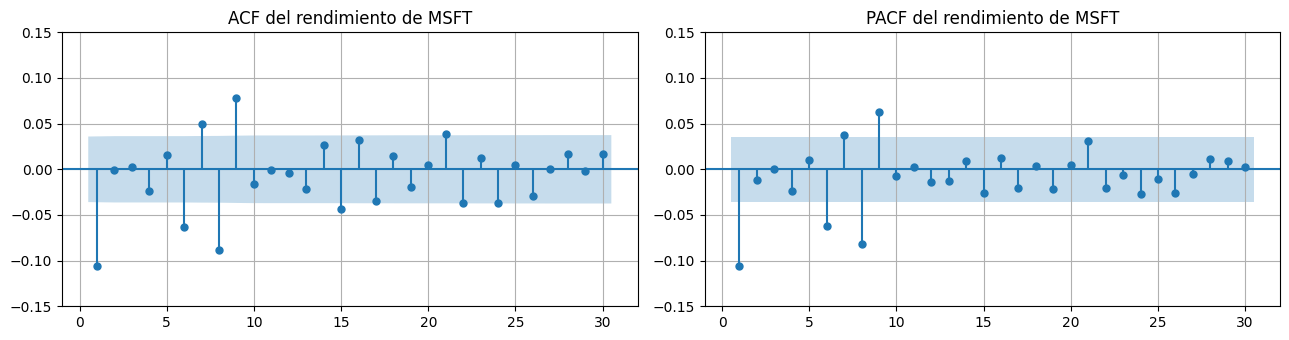

,p,q,AIC,BIC
0,0,1,-15406.7,-15388.8
1,1,0,-15406.7,-15388.7
2,1,2,-15413.6,-15383.7
3,2,0,-15404.8,-15380.9
4,1,1,-15404.8,-15380.9


ARIMA elegido por BIC: (0,1,1)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0009      0.000      3.022      0.003       0.000       0.001
ma.L1         -0.1064      0.010    -10.305      0.000      -0.127      -0.086
sigma2         0.0003   3.75e-06     79.450      0.000       0.000       0.000


,lb_stat,lb_pvalue
10,50.1678,0.0
20,62.5870,0.0


In [14]:
ACTIVO, H = "MSFT", 60
yv = np.log(precios[ACTIVO])
print(f"ADF log-precio p = {adfuller(yv, regression='ct', autolag='AIC')[1]:.4f} | ADF rendimiento p = {adfuller(yv.diff().dropna(), autolag='AIC')[1]:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(r[ACTIVO], lags=30, ax=ax[0], zero=False, title=f"ACF del rendimiento de {ACTIVO}")
plot_pacf(r[ACTIVO], lags=30, ax=ax[1], zero=False, method="ywm", title=f"PACF del rendimiento de {ACTIVO}")
for a in ax: a.set_ylim(-0.15, 0.15)
plt.tight_layout(); plt.show()

def seleccionar_arima(serie, pmax=3, qmax=3):
    res = []
    for p_ in range(pmax + 1):
        for q_ in range(qmax + 1):
            try:
                m = ARIMA(serie.values, order=(p_, 1, q_), trend="t").fit()
                res.append({"p": p_, "q": q_, "AIC": m.aic, "BIC": m.bic})
            except Exception:
                pass
    return pd.DataFrame(res).sort_values("BIC").reset_index(drop=True)

y_tr, y_te = yv.iloc[:-H], yv.iloc[-H:]
g = seleccionar_arima(y_tr)
display(g.head(5).round(1))
p_i, q_i = int(g.loc[0, "p"]), int(g.loc[0, "q"])
mod = ARIMA(y_tr.values, order=(p_i, 1, q_i), trend="t").fit()
print(f"ARIMA elegido por BIC: ({p_i},1,{q_i})"); print(mod.summary().tables[1])
lb = acorr_ljungbox(pd.Series(mod.resid[1:]), lags=[10, 20], model_df=p_i + q_i, return_df=True)
display(lb.round(4))

RMSE ARIMA = 13.218 | RMSE ingenuo = 24.598 | cobertura IC 95% = 100%


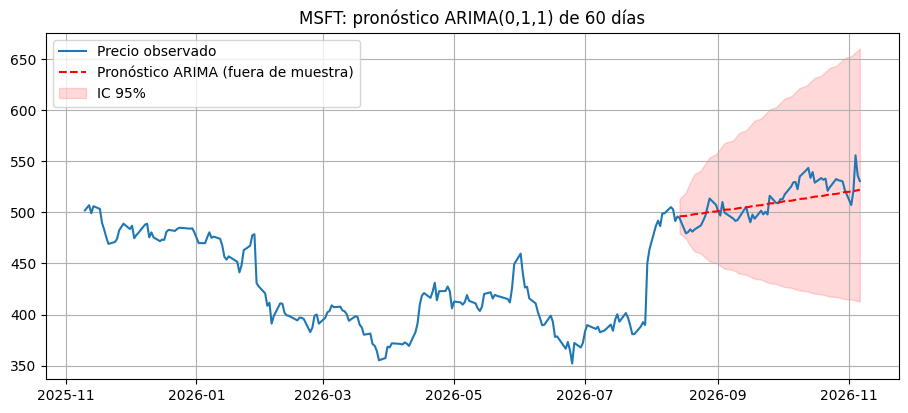

In [15]:
fc = mod.get_forecast(H)
media, ic = np.exp(fc.predicted_mean), np.exp(fc.conf_int(alpha=0.05))
real, ingenuo = np.exp(y_te.values), np.repeat(np.exp(y_tr.iloc[-1]), H)
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(f"RMSE ARIMA = {rmse(media, real):.3f} | RMSE ingenuo = {rmse(ingenuo, real):.3f} | cobertura IC 95% = {np.mean((real >= ic[:, 0]) & (real <= ic[:, 1])):.0%}")
plt.figure(figsize=(11, 4.5))
plt.plot(precios[ACTIVO].iloc[-250:], label="Precio observado")
plt.plot(y_te.index, media, "r--", label="Pronóstico ARIMA (fuera de muestra)")
plt.fill_between(y_te.index, ic[:, 0], ic[:, 1], color="r", alpha=0.15, label="IC 95%")
plt.title(f"{ACTIVO}: pronóstico ARIMA({p_i},1,{q_i}) de {H} días"); plt.legend(); plt.show()

**Interpretación.**
- **Identificación.** El log-precio de MSFT es no estacionario (ADF p = 0.60) y su rendimiento estacionario (p ≈ 0), por lo que $d = 1$. La ACF y la PACF del rendimiento tienen pocas barras fuera de las bandas.
- **Modelo elegido: ARIMA(0,1,1)** con tendencia. El término de promedio móvil es pequeño y negativo ($\theta_1 = -0.106$), es decir, una ligera reversión al día siguiente, la misma que se detectó para MSFT en la Tarea Clase 6 – 2.1. La deriva (0.09% diario) es significativa. En la práctica, el modelo es muy cercano a una **caminata aleatoria con deriva**. (En otra corrida de prueba el BIC eligió un ARIMA(2,1,2) con coeficientes AR y MA casi opuestos, que se cancelaban: la elección entre modelos casi equivalentes es inestable, una señal más de que hay poca estructura que explotar en la media.)
- **Diagnóstico.** Ljung-Box rechaza (p < 0.05), pero, como se mostró en la Tarea Clase 6 – 2.1, esa prueba sobrerrechaza cuando hay efectos ARCH; la dependencia restante está en la varianza, no en la media.
- **Pronóstico.** El error del ARIMA (13.2) es menor que el del pronóstico ingenuo (24.6), pero la ganancia viene de la **deriva**: en esos 60 días MSFT siguió subiendo, y el ingenuo supone precio constante. El intervalo de confianza al 95% contiene todos los precios observados y se abre con el horizonte, como corresponde a un proceso integrado.

<a id="sec-7-2"></a>
### 7.2 ARIMA para todo el universo

Para cada activo se repite el procedimiento: se elige el orden por BIC con los datos hasta 60 días antes del final, se verifica que los residuos sean ruido blanco (Ljung-Box) y se compara el pronóstico fuera de muestra con el **pronóstico ingenuo** (el último precio, que es el mejor pronóstico de una caminata aleatoria). Después se reestima con toda la muestra y se pronostican los **siguientes 20 días hábiles**.

In [16]:
filas, pron20 = [], {}
for k in ACTIVOS:
    yk = np.log(precios[k]); tr, te = yk.iloc[:-H], yk.iloc[-H:]
    gk = seleccionar_arima(tr)
    pk, qk = int(gk.loc[0, "p"]), int(gk.loc[0, "q"])
    mk = ARIMA(tr.values, order=(pk, 1, qk), trend="t").fit()
    f = mk.get_forecast(H); m_, c_ = np.exp(f.predicted_mean), np.exp(f.conf_int(alpha=0.05))
    re_, ing_ = np.exp(te.values), np.repeat(np.exp(tr.iloc[-1]), H)
    lbp = acorr_ljungbox(pd.Series(mk.resid[1:]), lags=[10], model_df=pk + qk, return_df=True)["lb_pvalue"].iloc[0]
    full = ARIMA(yk.values, order=(pk, 1, qk), trend="t").fit().get_forecast(20)
    pron20[k] = np.exp(full.predicted_mean)
    filas.append({"Activo": k, "ARIMA": f"({pk},1,{qk})", "Ljung-Box 10 (p)": lbp,
                  "RMSE ARIMA": rmse(m_, re_), "RMSE ingenuo": rmse(ing_, re_),
                  "ARIMA / ingenuo": rmse(m_, re_) / rmse(ing_, re_),
                  "Cobertura IC 95%": np.mean((re_ >= c_[:, 0]) & (re_ <= c_[:, 1])),
                  "Último precio": precios[k].iloc[-1], "Pronóstico 20 días": pron20[k][-1],
                  "Cambio esperado (%)": 100 * (pron20[k][-1] / precios[k].iloc[-1] - 1)})
arima_tab = pd.DataFrame(filas).set_index("Activo")
display(arima_tab.round(3))

,ARIMA,Ljung-Box 10 (p),RMSE ARIMA,RMSE ingenuo,ARIMA / ingenuo,Cobertura IC 95%,Último precio,Pronóstico 20 días,Cambio esperado (%)
Activo,,,,,,,,,
AAPL,"(0,1,0)",0.000,20.218,29.281,0.691,1.000,342.37,348.482,1.785
MSFT,"(0,1,1)",0.000,13.218,24.598,0.537,1.000,530.61,540.754,1.912
NVDA,"(1,1,0)",0.021,26.097,12.148,2.148,1.000,186.64,193.925,3.903
GOOGL,"(0,1,0)",0.000,31.908,23.467,1.360,1.000,284.78,289.348,1.604
JPM,"(3,1,3)",0.000,30.221,20.504,1.474,1.000,334.49,339.590,1.525
GS,"(0,1,0)",0.000,131.104,107.856,1.216,1.000,865.82,875.823,1.155
BAC,"(3,1,2)",0.017,10.009,8.827,1.134,0.983,49.42,49.719,0.605
XOM,"(0,1,0)",0.001,11.164,12.877,0.867,1.000,165.87,167.051,0.712
CVX,"(2,1,0)",0.000,17.131,19.431,0.882,1.000,212.61,213.948,0.630


**Interpretación.**
- **Órdenes elegidos.** En 6 de los 11 activos el BIC elige **ARIMA(0,1,0)**, es decir, una caminata aleatoria con deriva. Es lo que predijo la Tarea Clase 6 – 2.1: los rendimientos son prácticamente ruido blanco en la media.
- **Fuera de muestra, el ARIMA no le gana de forma consistente al pronóstico ingenuo:** es mejor en 5 activos (AAPL, MSFT, XOM, CVX y COP) y peor en 6. Las mejoras vienen de la deriva en activos que siguieron su tendencia; los empeoramientos, de activos que la rompieron (NVDA, por ejemplo, con un error 2.1 veces mayor que el ingenuo). La conclusión es la de un mercado **eficiente en forma débil**: la historia de precios casi no ayuda a pronosticar el nivel.
- **Intervalos.** La cobertura de los intervalos al 95% es de 97% a 100%: son anchos, porque reflejan honestamente la incertidumbre de un proceso integrado.
- **Pronóstico a 20 días.** Los cambios esperados son pequeños (entre −0.1% y 3.9%) y reflejan solo la deriva histórica. **No deben usarse como señal de compra**; el valor del pronóstico está en la banda de incertidumbre, no en el punto central.

<a id="sec-8"></a>
## 8. Volatilidad: GARCH (puntos extra)

<small>[↑ Volver al contenido](#contenido)</small>

Los rendimientos casi no tienen autocorrelación, pero su varianza sí: en la Tarea Clase 6 – 2.1 todos los activos mostraron efectos ARCH. Se estima un **GARCH(1,1)** con distribución $t$ de Student para cada activo:

$$r_t = \mu + u_t,\qquad u_t = \sigma_t z_t,\qquad \sigma_t^2 = \omega + \alpha\, u_{t-1}^2 + \beta\, \sigma_{t-1}^2$$

y se compara con un **GJR-GARCH**, que permite que las malas noticias aumenten más la volatilidad que las buenas (efecto apalancamiento, parámetro $\gamma$).

,ARCH-LM (p),α,β,α+β,ν (colas),Vida media (días),γ GJR,p γ,AIC GARCH,AIC GJR,Vol. actual anual (%),Vol. pronosticada 20 días anual (%),Vol. histórica anual (%)
Activo,,,,,,,,,,,,,
AAPL,0.0,0.105,0.870,0.975,4.345,27.114,0.145,0.000,11123.557,11081.774,33.867,32.295,28.644
MSFT,0.0,0.129,0.852,0.981,4.233,36.195,0.140,0.000,10767.630,10739.047,47.336,43.144,27.550
NVDA,0.0,0.081,0.895,0.976,4.432,28.799,0.119,0.001,14279.772,14243.272,60.446,57.580,47.748
GOOGL,0.0,0.059,0.937,0.996,3.913,179.859,0.082,0.001,11288.013,11263.091,52.604,50.916,29.221
JPM,0.0,0.131,0.818,0.949,4.665,13.267,0.153,0.002,10419.071,10378.336,37.640,32.221,26.817
GS,0.0,0.096,0.842,0.939,5.225,10.922,0.109,0.000,11331.134,11303.634,44.019,36.381,29.406
BAC,0.0,0.101,0.846,0.947,4.923,12.697,0.143,0.000,11347.206,11295.835,33.677,30.959,30.260
XOM,0.0,0.069,0.930,0.999,7.252,1018.918,0.029,0.031,10709.331,10706.881,34.720,33.870,27.511
CVX,0.0,0.070,0.919,0.989,5.101,59.973,0.035,0.018,10772.878,10769.334,30.034,29.026,29.078


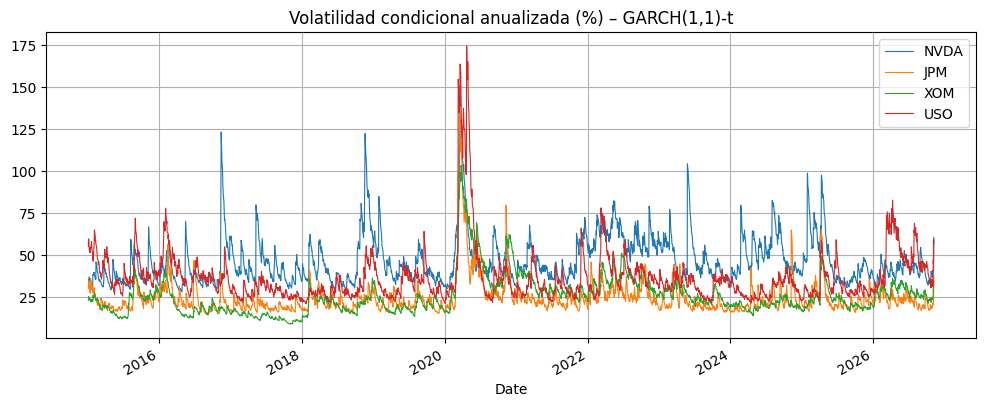

In [17]:
filas, garch = [], {}
for k in ACTIVOS:
    g11 = arch_model(r[k], mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    gjr = arch_model(r[k], mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
    garch[k] = g11
    a_, b_ = g11.params["alpha[1]"], g11.params["beta[1]"]
    v20 = np.sqrt(g11.forecast(horizon=20).variance.iloc[-1].values.mean())
    filas.append({"Activo": k, "ARCH-LM (p)": het_arch(r[k] - r[k].mean(), nlags=10)[1],
                  "α": a_, "β": b_, "α+β": a_ + b_, "ν (colas)": g11.params["nu"],
                  "Vida media (días)": np.log(0.5) / np.log(a_ + b_) if a_ + b_ < 1 else np.nan,
                  "γ GJR": gjr.params["gamma[1]"], "p γ": gjr.pvalues["gamma[1]"],
                  "AIC GARCH": g11.aic, "AIC GJR": gjr.aic,
                  "Vol. actual anual (%)": g11.conditional_volatility.iloc[-1] * np.sqrt(252),
                  "Vol. pronosticada 20 días anual (%)": v20 * np.sqrt(252),
                  "Vol. histórica anual (%)": r[k].std() * np.sqrt(252)})
garch_tab = pd.DataFrame(filas).set_index("Activo")
display(garch_tab.round(3))

fig, ax = plt.subplots(figsize=(12, 4.5))
for k in ["NVDA", "JPM", "XOM", "USO"]:
    (garch[k].conditional_volatility * np.sqrt(252)).plot(ax=ax, lw=0.8, label=k)
ax.set_title("Volatilidad condicional anualizada (%) – GARCH(1,1)-t"); ax.legend(); plt.show()

**Interpretación.**
- **Efectos ARCH en los 11 activos** (p ≈ 0): la varianza no es constante.
- **Persistencia muy alta:** α + β va de 0.94 (GS) a 0.999 (XOM). En bancos un choque de volatilidad se disipa a la mitad en 11 a 13 días; en GOOGL y XOM la persistencia es casi integrada, con vidas medias de 180 y más de 1,000 días.
- **Colas pesadas:** los grados de libertad de la $t$ van de 3.9 a 7.3, muy lejos de la normal; los eventos extremos son más frecuentes de lo que supone la distribución normal.
- **Efecto apalancamiento:** el parámetro γ del GJR-GARCH es positivo y significativo en los 11 activos, y el GJR tiene menor AIC en todos: **las caídas elevan más la volatilidad que las subidas de igual tamaño**. El efecto es más fuerte en tecnología y bancos (γ de 0.08 a 0.15) que en energía (0.03 a 0.07).
- **Volatilidad actual.** Al cierre del periodo, la volatilidad condicional está **por encima de su promedio histórico** en todos los activos (por ejemplo, MSFT 47% contra 28%; GOOGL 53% contra 29%), reflejo de la turbulencia de finales de octubre de 2026. El pronóstico a 20 días **revierte gradualmente hacia la media**, como predice el modelo.
- **Implicación:** el riesgo, a diferencia del rendimiento, sí es pronosticable. Es la base de la construcción de portafolios de la sección 9.

<a id="sec-9"></a>
## 9. Portafolio: covarianza pronosticada, comparación y simulación de escenarios

<small>[↑ Volver al contenido](#contenido)</small>

<a id="sec-9-1"></a>
### 9.1 Portafolios comparados

Con las volatilidades pronosticadas por GARCH y la correlación de los residuos estandarizados se construye la **matriz de covarianza pronosticada** (modelo de correlación condicional constante, CCC), como en el cuaderno guía del curso. Se comparan tres portafolios:

1. **Pesos iguales (1/N).**
2. **Mínima varianza** con la covarianza GARCH, solo posiciones largas.
3. **Portafolio real** de HowTheMarketWorks, con las cantidades de acciones al cierre de la competencia (incluida la posición corta en GS).

Los modelos se estiman con datos hasta 60 días antes del final y se evalúan en esos 60 días **fuera de muestra**.

,Iguales (1/N) (%),Mínima varianza (GARCH) (%),Real (HowTheMarketWorks) (%)
AAPL,9.1,19.9,24.5
MSFT,9.1,0.6,25.6
NVDA,9.1,3.7,1.5
GOOGL,9.1,0.6,1.6
JPM,9.1,42.5,23.9
GS,9.1,0.0,-6.3
BAC,9.1,0.0,1.7
XOM,9.1,19.1,22.8
CVX,9.1,12.6,1.2
COP,9.1,0.0,1.2


,Iguales (1/N),Mínima varianza (GARCH),Real (HowTheMarketWorks)
Vol. pronosticada anual (%),22.26,20.23,23.13
Vol. realizada anual (%),12.58,13.23,13.34
VaR 95% 1 día (%),2.31,2.10,2.40
Rend. acumulado fuera de muestra (%),-2.80,0.43,4.68
Peor día (%),-3.19,-3.19,-2.70


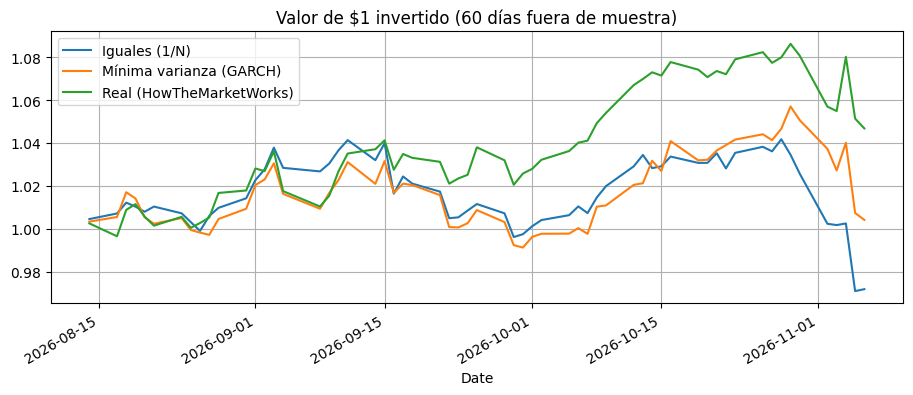

In [18]:
# Cantidades del portafolio real en HowTheMarketWorks (negativo = venta en corto).
# Posiciones previas más las compras de NVDA, GOOGL, BAC, CVX y COP del 9 de noviembre de 2026.
HTMW = {"XOM": 1316, "MSFT": 470, "JPM": 602, "AAPL": 730, "USO": 170, "GS": -55,
        "NVDA": 62, "GOOGL": 42, "BAC": 242, "CVX": 56, "COP": 88}

H = 60
tr, te = r.iloc[:-H], r.iloc[-H:]
vols, zres = {}, {}
for k in ACTIVOS:
    m = arch_model(tr[k], mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    vols[k] = np.sqrt(m.forecast(horizon=H).variance.iloc[-1].values.mean())
    zres[k] = m.std_resid
vols = pd.Series(vols)
R = pd.DataFrame(zres).corr()
Sigma = np.diag(vols.values) @ R.values @ np.diag(vols.values)
var_p = lambda w: float(w @ Sigma @ w)

n = len(ACTIVOS)
w_eq = np.repeat(1 / n, n)
w_mv = minimize(var_p, w_eq, method="SLSQP", bounds=[(0, 1)] * n,
                constraints={"type": "eq", "fun": lambda w: w.sum() - 1}).x
valor = pd.Series(HTMW).reindex(ACTIVOS).fillna(0) * precios.iloc[-H - 1][ACTIVOS]
w_real = (valor / valor.sum()).values

pesos = pd.DataFrame({"Iguales (1/N)": w_eq, "Mínima varianza (GARCH)": w_mv, "Real (HowTheMarketWorks)": w_real}, index=ACTIVOS)
display((100 * pesos).round(1).rename(columns=lambda c: c + " (%)"))

res = {}
for nombre, w in pesos.items():
    rp = te @ w.values
    sig_ = np.sqrt(var_p(w.values))
    res[nombre] = {"Vol. pronosticada anual (%)": sig_ * np.sqrt(252), "Vol. realizada anual (%)": rp.std() * np.sqrt(252),
                   "VaR 95% 1 día (%)": 1.645 * sig_, "Rend. acumulado fuera de muestra (%)": (np.exp(rp.sum() / 100) - 1) * 100,
                   "Peor día (%)": rp.min()}
display(pd.DataFrame(res).round(2))
pd.DataFrame({nombre: np.exp((te @ w.values).cumsum() / 100) for nombre, w in pesos.items()}, index=te.index).plot(
    title="Valor de $1 invertido (60 días fuera de muestra)"); plt.show()

**Interpretación.**

- **Composición.** El portafolio de **mínima varianza** concentra el capital en los activos de menor volatilidad pronosticada y menor correlación entre sí: JPM (42.5%), AAPL (19.9%), XOM (19.1%) y CVX (12.6%), combinando los tres sectores. El **portafolio real** está concentrado en cuatro posiciones grandes (MSFT 25.6%, AAPL 24.5%, JPM 23.9% y XOM 22.8%), con la posición corta en GS (−6.3%) y las cinco compras nuevas con pesos de 1.2% a 1.7% cada una.
- **Riesgo pronosticado.** El de mínima varianza tiene la menor volatilidad pronosticada (20.2% anual) y el menor VaR (2.10% diario), frente a 22.3% del de pesos iguales y 23.1% del real. La diversificación entre sectores con motores distintos (mercado, tasas, petróleo) reduce el riesgo.
- **Fuera de muestra (60 días).** El portafolio **real** obtuvo el mayor rendimiento (+4.7%), frente a +0.4% del de mínima varianza y −2.8% del de pesos iguales. Su mayor exposición a tecnología y bancos funcionó en ese periodo. Las volatilidades realizadas (12.6% a 13.3%) fueron **menores** que las pronosticadas: el GARCH, estimado con datos que terminan en un periodo turbulento, fue conservador. Las tres estrategias quedan en un orden de riesgo parecido y el peor día de todas estuvo alrededor de −3%.
- **Lectura:** el portafolio real ganó más con un riesgo apenas mayor, pero está **concentrado**; el de mínima varianza ofrece la mejor protección. Para un cliente, el punto de partida debería ser una combinación de ambos (sección 11).

<a id="sec-9-2"></a>
### 9.2 Simulación de escenarios (Monte Carlo)

Para visualizar los escenarios posibles, se simulan **10,000 trayectorias de 60 días hábiles** del valor de cada portafolio, con rendimientos diarios multivariados que usan la media histórica y la **covarianza pronosticada por GARCH**. El valor inicial es de USD 1,000,000.

,Iguales (1/N),Mínima varianza (GARCH),Real (HowTheMarketWorks)
P5 (pesimista),872221.8,887143.7,867425.5
Mediana,1042448.0,1039652.5,1047764.7
P95 (optimista),1244662.6,1222922.8,1256057.0
Prob. de pérdida (%),35.0,34.6,34.2
VaR 95% 60 días (USD),127778.2,112856.3,132574.5


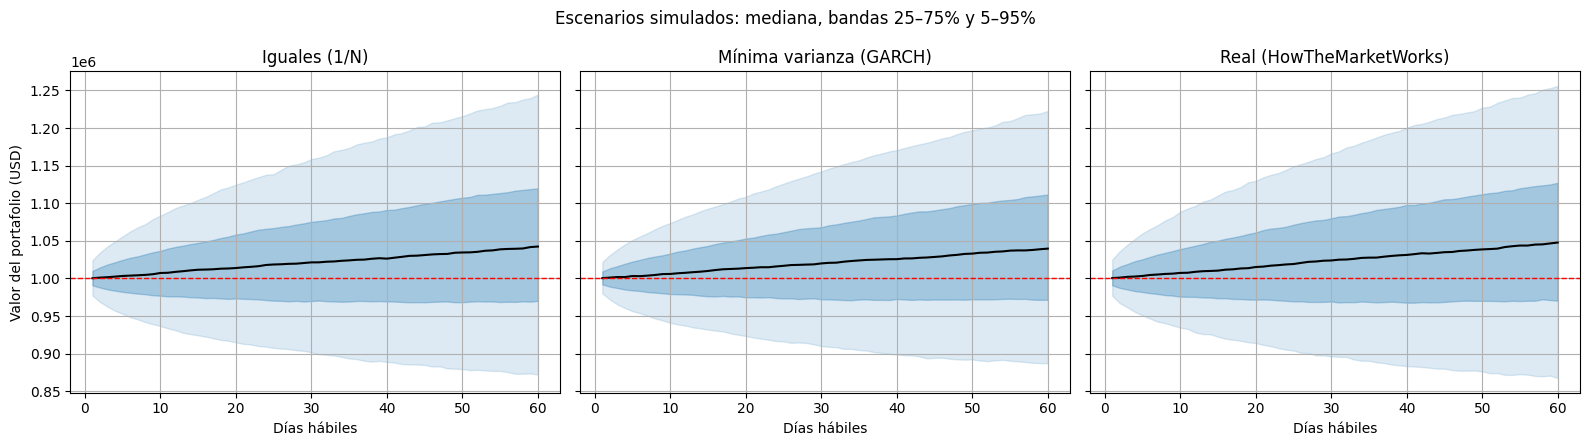

In [19]:
rng = np.random.default_rng(2026)
N_SIM, DIAS, V0 = 10_000, 60, 1_000_000
mu = r.mean().values
Lc = np.linalg.cholesky(Sigma + 1e-10 * np.eye(n))
sim = {}
for nombre, w in pesos.items():
    z = rng.standard_normal((N_SIM, DIAS, n)) @ Lc.T + mu
    rp = z @ w.values / 100
    sim[nombre] = V0 * np.exp(np.cumsum(rp, axis=1))

escen = pd.DataFrame({nombre: {"P5 (pesimista)": np.percentile(v[:, -1], 5), "Mediana": np.median(v[:, -1]),
                               "P95 (optimista)": np.percentile(v[:, -1], 95),
                               "Prob. de pérdida (%)": 100 * np.mean(v[:, -1] < V0),
                               "VaR 95% 60 días (USD)": V0 - np.percentile(v[:, -1], 5)} for nombre, v in sim.items()})
display(escen.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (nombre, v) in zip(axes, sim.items()):
    for qq, a in [(5, 0.15), (25, 0.3)]:
        ax.fill_between(range(1, DIAS + 1), np.percentile(v, qq, axis=0), np.percentile(v, 100 - qq, axis=0), alpha=a, color="tab:blue")
    ax.plot(range(1, DIAS + 1), np.median(v, axis=0), "k", lw=1.5)
    ax.axhline(V0, color="r", ls="--", lw=1); ax.set_title(nombre); ax.set_xlabel("Días hábiles")
axes[0].set_ylabel("Valor del portafolio (USD)")
plt.suptitle("Escenarios simulados: mediana, bandas 25–75% y 5–95%"); plt.tight_layout(); plt.show()

**Interpretación.**

- En la **mediana** de los escenarios, los tres portafolios terminan con alrededor de USD 1.04 a 1.05 millones a 60 días hábiles (unos tres meses), una ganancia de 4% a 5%.
- La **probabilidad de pérdida** es parecida en los tres (34% a 35%): en un horizonte de tres meses, uno de cada tres escenarios termina abajo del capital inicial.
- El **escenario pesimista** (percentil 5) marca la diferencia: el VaR al 95% a 60 días es de USD 112,856 en el de mínima varianza, USD 127,778 en el de pesos iguales y USD 132,575 en el real. Es decir, con una probabilidad de 5% la pérdida a tres meses superaría 11.3%, 12.8% y 13.3%, respectivamente.
- El **escenario optimista** (percentil 95) favorece al portafolio real (USD 1.26 millones), por su mayor exposición a activos más volátiles.
- **Limitaciones:** la simulación usa rendimientos normales con la covarianza GARCH, por lo que subestima las colas pesadas (sección 8), y supone que las correlaciones se mantienen. Los escenarios extremos reales pueden ser peores.

<a id="sec-10"></a>
## 10. Análisis técnico: MACD y RSI

<small>[↑ Volver al contenido](#contenido)</small>

El caso de Capital Analyst propone usar indicadores técnicos para seleccionar acciones (Ramlall, 2016):

- **MACD:** diferencia entre las medias móviles exponenciales de 12 y 26 días; la **señal** es su media móvil de 9 días. MACD por encima de la señal indica impulso alcista.
- **RSI(14):** índice de fuerza relativa entre 0 y 100. Arriba de 70 se considera **sobrecompra**; abajo de 30, **sobreventa**.

<a id="sec-10-1"></a>
### 10.1 Señales al cierre del periodo

In [20]:
def macd(p):
    m = p.ewm(span=12, adjust=False).mean() - p.ewm(span=26, adjust=False).mean()
    return m, m.ewm(span=9, adjust=False).mean()

def rsi(p, n=14):
    d = p.diff()
    ganan = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    pierde = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + ganan / pierde)

filas = []
for k in ACTIVOS:
    m, s = macd(precios[k]); rr = rsi(precios[k])
    cruce = np.sign(m - s).diff().fillna(0)
    ult = cruce[cruce != 0].index[-1].date() if (cruce != 0).any() else None
    filas.append({"Activo": k, "RSI(14)": rr.iloc[-1],
                  "Zona RSI": "Sobrecompra" if rr.iloc[-1] > 70 else "Sobreventa" if rr.iloc[-1] < 30 else "Neutral",
                  "MACD": m.iloc[-1], "Señal": s.iloc[-1], "Tendencia MACD": "Alcista" if m.iloc[-1] > s.iloc[-1] else "Bajista",
                  "Último cruce": ult})
tecnico = pd.DataFrame(filas).set_index("Activo")
display(tecnico.round(2))

,RSI(14),Zona RSI,MACD,Señal,Tendencia MACD,Último cruce
Activo,,,,,,
AAPL,51.46,Neutral,2.07,2.84,Bajista,2026-10-28
MSFT,52.15,Neutral,4.38,4.97,Bajista,2026-10-19
NVDA,30.77,Neutral,-8.23,-5.03,Bajista,2026-10-12
GOOGL,29.92,Sobreventa,-16.57,-12.78,Bajista,2026-10-16
JPM,46.74,Neutral,0.36,-0.25,Alcista,2026-10-12
GS,40.30,Neutral,-9.84,-10.45,Alcista,2026-10-12
BAC,34.52,Neutral,-1.42,-1.59,Alcista,2026-10-26
XOM,39.38,Neutral,0.88,3.23,Bajista,2026-11-03
CVX,40.63,Neutral,1.73,4.23,Bajista,2026-11-03


<a id="sec-10-2"></a>
### 10.2 Prueba retrospectiva (*backtesting*) de la estrategia MACD

Estrategia: mantener la acción mientras el MACD esté por encima de su señal y quedarse en efectivo en caso contrario. La señal de un día se ejecuta al día siguiente, para no usar información futura. Se compara con comprar y mantener (*buy and hold*), sin costos de transacción.

In [21]:
def metricas(rd):
    anual = rd.mean() * 252; vol = rd.std() * np.sqrt(252)
    nivel = np.exp(rd.cumsum() / 100)
    return anual, vol, (anual - rf_anual) / vol, (nivel / nivel.cummax() - 1).min() * 100

filas = []
for k in ACTIVOS:
    m, s = macd(precios[k])
    pos = (m > s).astype(int).shift(1).reindex(r.index).fillna(0)
    bh, st = metricas(r[k]), metricas(r[k] * pos)
    filas.append({"Activo": k, "B&H rend. anual (%)": bh[0], "MACD rend. anual (%)": st[0],
                  "B&H Sharpe": bh[2], "MACD Sharpe": st[2], "B&H máx. caída (%)": bh[3], "MACD máx. caída (%)": st[3],
                  "Días invertido (%)": 100 * pos.mean(), "Operaciones": int(pos.diff().abs().sum())})
bt = pd.DataFrame(filas).set_index("Activo")
display(bt.round(2))
print(f"MACD supera a B&H en Sharpe en {(bt['MACD Sharpe'] > bt['B&H Sharpe']).sum()} de {len(bt)} activos.")

,B&H rend. anual (%),MACD rend. anual (%),B&H Sharpe,MACD Sharpe,B&H máx. caída (%),MACD máx. caída (%),Días invertido (%),Operaciones
Activo,,,,,,,,
AAPL,22.42,19.08,0.71,0.94,-38.52,-26.74,51.56,212
MSFT,21.95,3.77,0.72,0.09,-37.15,-41.90,50.18,250
NVDA,50.41,20.69,1.01,0.57,-66.34,-52.17,51.80,248
GOOGL,20.17,9.46,0.62,0.37,-44.32,-42.54,50.86,250
JPM,16.81,11.27,0.55,0.53,-43.63,-35.71,50.39,229
GS,14.60,8.99,0.43,0.37,-48.75,-38.41,50.82,229
BAC,10.68,15.02,0.28,0.66,-48.95,-35.83,51.16,217
XOM,9.07,5.31,0.25,0.17,-61.34,-28.60,52.77,230
CVX,9.61,5.89,0.26,0.20,-55.77,-32.44,52.33,244


MACD supera a B&H en Sharpe en 4 de 11 activos.


**Interpretación.**
- **Señales actuales.** Al 6 de noviembre de 2026, 8 de los 11 activos tienen el MACD por debajo de su señal (impulso **bajista**): las cuatro tecnológicas, las tres petroleras y USO. Solo los tres bancos muestran impulso alcista, con cruces recientes. **GOOGL** está en **sobreventa** (RSI 29.9) tras su caída del 29 de octubre, y NVDA está en el límite (30.8). Es congruente con la alta volatilidad estimada por GARCH.
- **Backtesting.** La estrategia MACD supera a comprar y mantener en Sharpe solo en **4 de 11** activos (AAPL, BAC, COP y USO), y reduce el rendimiento anual en 8. Su ventaja es la **protección ante caídas**: reduce la caída máxima en 10 de 11 activos (por ejemplo, XOM de −61% a −29%), porque sale del mercado en las tendencias bajistas prolongadas.
- **Limitaciones:** no incluye costos de transacción, y con más de 200 operaciones en 12 años esos costos reducirían aún más su rendimiento. En línea con la eficiencia débil (secciones 7 y 8), el análisis técnico sirve más para **gestionar el riesgo y el momento de entrada** que para generar rendimientos superiores.

<a id="sec-11"></a>
## 11. Estrategia y propuesta a Capital Analyst

<small>[↑ Volver al contenido](#contenido)</small>

### 11.1 Horizonte, perfil de riesgo y universo

- **Horizonte de inversión:** mediano plazo, de 6 a 12 meses, con revisión mensual. Los modelos muestran que el rendimiento de corto plazo es prácticamente impredecible (secciones 7 y 10), así que la estrategia no debe depender de pronósticos de precio a días o semanas.
- **Perfil de riesgo:** moderado-agresivo. El portafolio propuesto tiene una volatilidad pronosticada de alrededor de 20% a 23% anual y un VaR al 95% a tres meses de 11% a 13% del capital. Para un cliente conservador habría que agregar renta fija o efectivo.
- **Universo:** se mantienen las 10 acciones, porque cubren tres sectores con motores de riesgo distintos (sección 5). Se propone **reducir o eliminar USO**: tiene rendimiento y Sharpe negativos y una caída máxima de −90% por el costo de renovar futuros; la exposición al petróleo se obtiene mejor con XOM, CVX y COP.

### 11.2 Estrategia propuesta

1. **Asignación base guiada por el riesgo.** Partir de una combinación del portafolio de mínima varianza (mejor protección) y del portafolio real (mejor rendimiento reciente), reduciendo la concentración: ninguna acción por encima de alrededor de 20% y cada sector con un peso relevante. Hoy el portafolio real tiene alrededor de 97% en cuatro acciones, más la posición corta; las cinco compras nuevas, de 1% a 2% cada una, son un primer paso hacia la diversificación.
2. **Tamaño de las posiciones con GARCH.** Ajustar los pesos según la volatilidad pronosticada: menos peso cuando la volatilidad está alta, como al cierre del periodo (sección 8). La persistencia alta implica que un periodo turbulento dura semanas.
3. **Selección con fundamentales.** Dar preferencia a las empresas con **crecimiento de ingresos** sostenido, que el mercado premia (sección 6), y desconfiar de los ROE excepcionalmente altos, que tienden a normalizarse.
4. **Gestión del riesgo con indicadores técnicos.** Usar el MACD como **filtro de salida** en tendencias bajistas prolongadas, no como fuente de rendimiento: reduce las caídas máximas en 10 de 11 activos, pero rara vez mejora el rendimiento (sección 10). Mantener órdenes *stop* en las posiciones cortas, como la de GS a USD 949.
5. **Coberturas según el factor de riesgo.** Los bancos dependen de las tasas y la energía del petróleo (sección 5): ante un escenario de baja de tasas, reducir bancos; ante una caída del petróleo, reducir energía.
6. **Automatización.** Reestimar mensualmente los modelos de este cuaderno (los datos se descargan automáticamente) y, como siguiente paso, conectar las órdenes con la API de Interactive Brokers, como propone el caso.

### 11.3 Situación actual (6 de noviembre de 2026)

Al cierre del periodo la volatilidad está por encima de su promedio histórico en todos los activos y 8 de 11 muestran impulso bajista en el MACD. La recomendación táctica es **no aumentar la exposición de golpe**: completar la diversificación de forma gradual, empezando por los bancos (impulso alcista) y aprovechando la sobreventa de GOOGL solo cuando el MACD confirme un cambio de tendencia.

<a id="sec-12"></a>
## 12. Evidencias: operaciones en HowTheMarketWorks

<small>[↑ Volver al contenido](#contenido)</small>

Como parte del portafolio del concurso de HowTheMarketWorks, el 9 de noviembre de 2026 se colocaron órdenes de compra a mercado para completar el universo de 10 acciones: NVDA (62), GOOGL (42), BAC (242), CVX (56) y COP (88), por USD 59,141.62 incluidas las comisiones, sin usar los fondos de la venta en corto de GS, que se mantienen como respaldo de esa posición.

**Posiciones previas (8 de noviembre de 2026):**

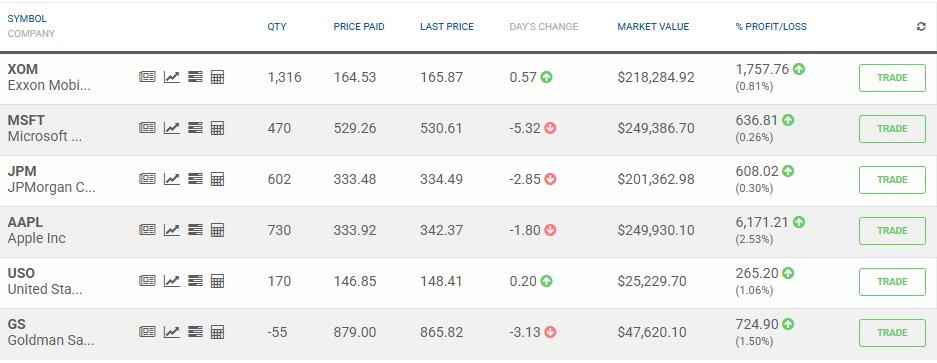

**Historial de órdenes: las cinco compras del 9 de noviembre de 2026 ejecutadas (*Filled*) y las operaciones anteriores, incluida la venta en corto de GS y su orden *stop* de protección a USD 949:**

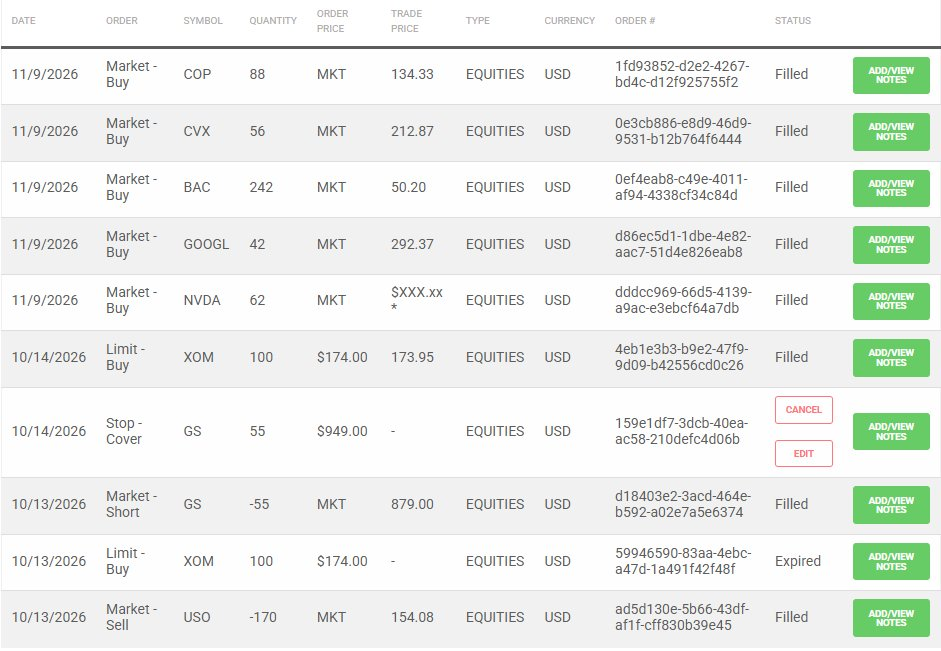

**Portafolio con todas las posiciones abiertas después de la ejecución (9 de noviembre de 2026):**

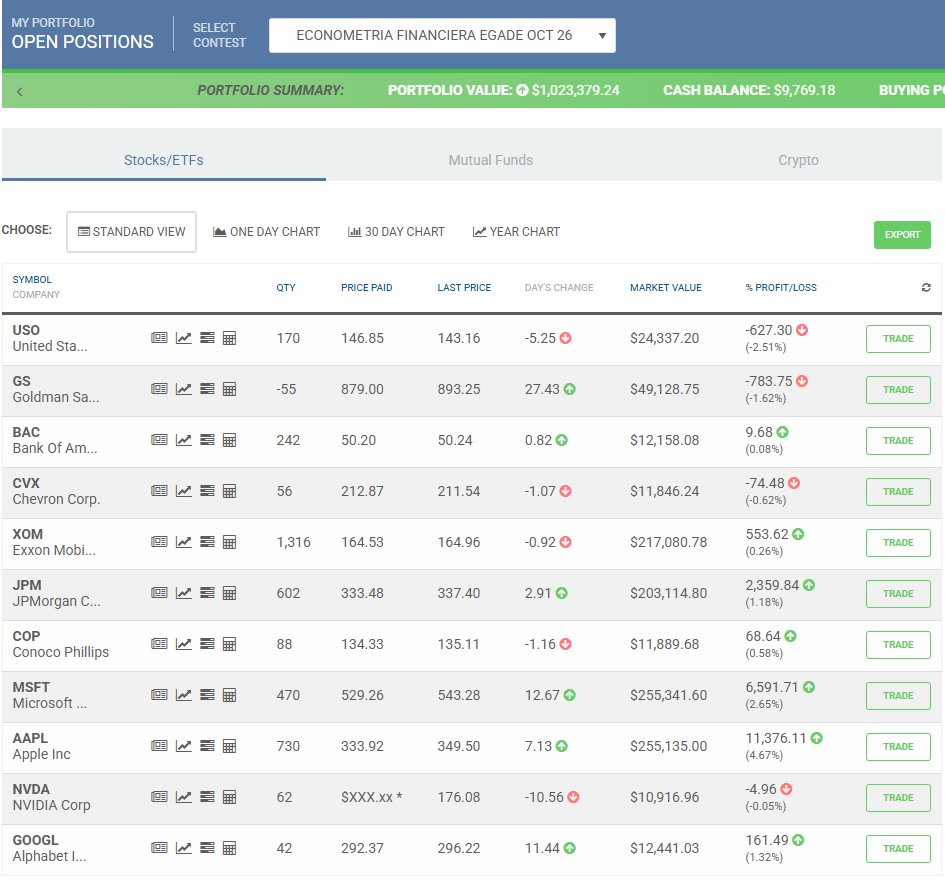

En la plataforma, el precio de compra de NVDA aparece como "$XXX.xx *". Se puede obtener de la propia pantalla: el valor de mercado (USD 10,916.96) más la pérdida mostrada (USD 4.96) da un costo de USD 10,921.92, es decir, alrededor de USD 176.16 por acción. La cifra cuadra con el efectivo: la caja bajó de USD 68,910.80 a USD 9,769.18, una diferencia de USD 59,141.62, igual al costo de las cinco compras más USD 50 de comisiones.

<a id="sec-13"></a>
## 13. Conclusiones

<small>[↑ Volver al contenido](#contenido)</small>

1. **Datos.** Se construyó un flujo reproducible que descarga y depura precios diarios de 11 activos y 5 factores de mercado (2015–2026) y combina reportes trimestrales de LSEG de 10 empresas.
2. **Riesgo y rendimiento.** Tecnología ofreció el mejor rendimiento ajustado por riesgo (NVDA con Sharpe de 1.01), energía el peor entre las acciones, y USO destruyó valor (−90% de caída máxima).
3. **Regresión simple.** Tecnología y bancos son agresivos (β > 1) y energía defensiva; el mercado explica de 43% a 57% del riesgo en tecnología y bancos, pero solo de 24% a 30% en energía. Solo NVDA generó un α significativo.
4. **Regresión múltiple.** Cada sector tiene su propio motor: **tasas** en bancos, **petróleo** en energía y **mercado** en tecnología. Los factores adicionales son significativos en los 11 activos y elevan el R² de USO de 0.06 a 0.81. Un hallazgo contrario a lo esperado: el dólar fuerte se asocia con rendimientos mayores en tecnología.
5. **Datos panel.** La prueba de Hausman llevó a efectos fijos, y por la dependencia transversal se usaron errores de Driscoll-Kraay. El **crecimiento de ingresos** se asocia positivamente con el rendimiento del trimestre siguiente, el ROE alto respecto de su promedio negativamente (reversión a la media) y el mercado domina la explicación.
6. **ARIMA.** En la mayoría de los activos el mejor modelo es prácticamente una caminata aleatoria con deriva, y fuera de muestra no le gana de forma consistente al pronóstico ingenuo: el **nivel de los precios no es pronosticable** con su propia historia (eficiencia débil).
7. **GARCH.** La **volatilidad sí es pronosticable**: alta persistencia, colas pesadas y efecto apalancamiento en los 11 activos. Es la información más útil de los modelos de series de tiempo para la toma de decisiones.
8. **Portafolio y escenarios.** La covarianza pronosticada con GARCH permite construir un portafolio de mínima varianza con el menor riesgo; el portafolio real obtuvo el mayor rendimiento reciente, pero está concentrado. La simulación indica una probabilidad de pérdida de alrededor de 35% a tres meses y un VaR al 95% de 11% a 13%.
9. **Análisis técnico.** El MACD no mejora el rendimiento de forma consistente, pero sí reduce las caídas máximas: es una herramienta de gestión de riesgo.
10. **Propuesta.** Capital Analyst debería combinar diversificación sectorial, asignación guiada por la volatilidad pronosticada, selección por crecimiento de ingresos y reglas de salida, con reestimación mensual automatizada.

**Limitaciones generales:** las relaciones estimadas son asociaciones, no causalidad; el periodo incluye el choque de 2020; la simulación supone normalidad; y el backtesting no incluye costos de transacción. Ningún resultado es una recomendación de inversión real.

<a id="sec-14"></a>
## 14. Referencias

<small>[↑ Volver al contenido](#contenido)</small>

Bernal, L. A. (2023). *Algorithms and financial programming in R*. https://www.arturo-bernal.com/books.html

Brooks, C. (2008). *Introductory econometrics for finance* (2.ª ed.). Cambridge University Press.

Díaz Robles, R. (2023). *Automation of algorithms in Capital Analyst portfolios* (Nota técnica 2-NE02-06-193). International Case Center, Tecnológico de Monterrey.

Gujarati, D. N., y Porter, D. C. (2009). *Econometría* (5.ª ed.). McGraw-Hill. Capítulos 16, 21 y 22.

Hoechle, D. (2007). Robust standard errors for panel regressions with cross-sectional dependence. *The Stata Journal, 7*(3), 281–312.

LSEG. (2026). *LSEG Workspace: estados financieros trimestrales* [Base de datos]. London Stock Exchange Group.

Ramlall, I. (2016). *Applied technical analysis for advanced learners and practitioners*. Emerald Group Publishing.

Wooldridge, J. M. (2020). *Introductory econometrics: A modern approach* (7.ª ed.). Cengage.

Yahoo Finance. (2026). *Precios históricos diarios* [Conjunto de datos], consultado mediante la librería `yfinance`.

---

**Nota sobre el uso de inteligencia artificial.** Para elaborar el código en Python y apoyar la redacción se utilizó Claude (Anthropic) como asistente, y GitHub Copilot para la revisión del código. Los cálculos se ejecutaron en Google Colab y los resultados e interpretaciones fueron revisados por el alumno.